In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salader/dogsvscats")

print("Path to dataset files:", path)

Path to dataset files: /home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1


In [2]:
import os

print(path)
print(os.listdir(path))

/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1
['train', 'test', 'catsvsdogs']


In [3]:
import os

train_path = os.path.join(path, "train")

print(os.listdir(train_path))


['cats', 'dogs']


In [4]:
import os

print("train:", len(os.listdir(os.path.join(path, "train"))))
print("test :", len(os.listdir(os.path.join(path, "test"))))

train: 2
test : 2


In [5]:
for root, dirs, files in os.walk(os.path.join(path, "catsvsdogs")):
    print(root)
    print("dirs:", dirs)
    print("num_files:", len(files))
    print("-"*50)

/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs
dirs: ['train', 'test']
num_files: 0
--------------------------------------------------
/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs/train
dirs: ['cats', 'dogs']
num_files: 0
--------------------------------------------------
/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs/train/cats
dirs: []
num_files: 10000
--------------------------------------------------
/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs/train/dogs
dirs: []
num_files: 10000
--------------------------------------------------
/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs/test
dirs: ['cats', 'dogs']
num_files: 0
--------------------------------------------------
/home/bhagat-singh/.cache/kagglehub/datasets/salader/dogsvscats/versions/1/catsvsdogs/test/cats
dirs: []
num_files: 2500


In [6]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(256, 256),
    batch_size=16
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(256, 256),
    batch_size=16
)
print(len(train_ds))
print(len(val_ds))

I0000 00:00:1795456568.317818    1488 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795456569.202612    1488 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795456571.488187    1488 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Found 20000 files belonging to 2 classes.
Using 16000 files for training.


I0000 00:00:1795456576.316304    1488 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
1000
250


In [7]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

In [8]:
for images, labels in train_ds.take(1):
    print(images.shape)
    print(labels.shape)


(16, 256, 256, 3)
(16,)


In [9]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from keras.regularizers import l2
import matplotlib.pyplot as plt
from keras.regularizers import L2
from keras.callbacks import EarlyStopping

In [10]:
# ==========================================
# DATA AUGMENTATION
# ==========================================

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1)
])

# ==========================================
# MODEL
# ==========================================

model = Sequential()

# Input Layer
model.add(Input(shape=(256, 256, 3)))

# Data Augmentation
model.add(data_augmentation)

# Block 1
model.add(
    Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(BatchNormalization())
model.add(MaxPooling2D())

# Block 2
model.add(
    Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(BatchNormalization())
model.add(MaxPooling2D())

# Block 3
model.add(
    Conv2D(
        128,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(BatchNormalization())
model.add(MaxPooling2D())

# Block 4
model.add(
    Conv2D(
        256,
        (3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(BatchNormalization())

model.add(MaxPooling2D())

# Global Average Pooling
model.add(GlobalAveragePooling2D())

# Dense Layer 1
model.add(
    Dense(
        128,
        activation='relu',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(Dropout(0.4))

# Dense Layer 2
model.add(
    Dense(
        64,
        activation='relu',
        kernel_regularizer=L2(1e-4)
    )
)
model.add(Dropout(0.3))

# Output Layer
model.add(Dense(1, activation='sigmoid'))

# ==========================================
# SUMMARY
# ==========================================

model.summary()

# ==========================================
# COMPILE
# ==========================================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 431,553 (1.65 MB)

 Trainable params: 430,593 (1.64 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [12]:
history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=[early_stop]
)

Epoch 1/30


/home/bhagat-singh/deep_learning/tfenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795456584.082837    1704 cuda_dnn.cc:461] Loaded cuDNN version 92801


1000/1000 ━━━━━━━━━━━━━━━━━━━━ 142s 134ms/step - accuracy: 0.5886 - loss: 0.7261 - val_accuracy: 0.6305 - val_loss: 0.6872
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 137s 137ms/step - accuracy: 0.6389 - loss: 0.6842 - val_accuracy: 0.6170 - val_loss: 0.6708
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 138s 138ms/step - accuracy: 0.6676 - loss: 0.6512 - val_accuracy: 0.6845 - val_loss: 0.6270
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 135s 135ms/step - accuracy: 0.6944 - loss: 0.6252 - val_accuracy: 0.6580 - val_loss: 0.7008
Epoch 5/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 140s 140ms/step - accuracy: 0.7115 - loss: 0.6029 - val_accuracy: 0.5705 - val_loss: 0.8735
Epoch 6/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 140s 140ms/step - accuracy: 0.7573 - loss: 0.5518 - val_accuracy: 0.6068 - val_loss: 1.7858
Epoch 7/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 145s 145ms/step - accuracy: 0.7939 - loss: 0.5060 - val_accuracy: 0.5602 - val_loss: 3.2835
Epoch 8/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 144s 144ms/step - accuracy: 0.8

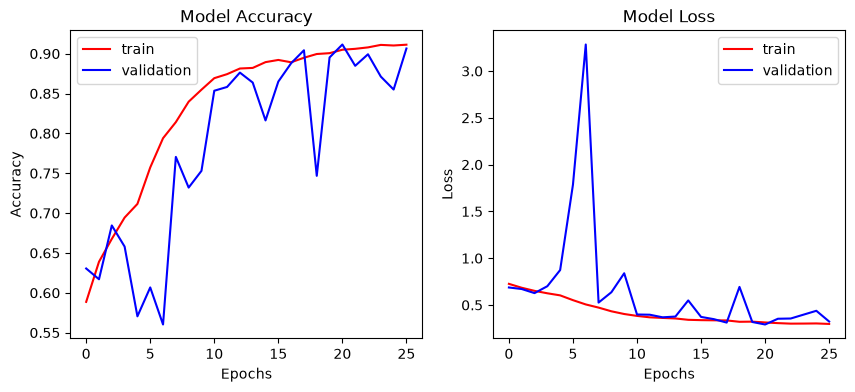

In [13]:
# ==========================================
# 6. EVALUATION (LOSS & ACCURACY PLOTS)
# ==========================================
# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [14]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(path, "test"),
    image_size=(256,256),
    batch_size=16,
    shuffle=False
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)


Found 5000 files belonging to 2 classes.


In [15]:
for images, labels in test_ds.take(1):
    print(images.numpy().min())
    print(images.numpy().max())

0.0
1.0


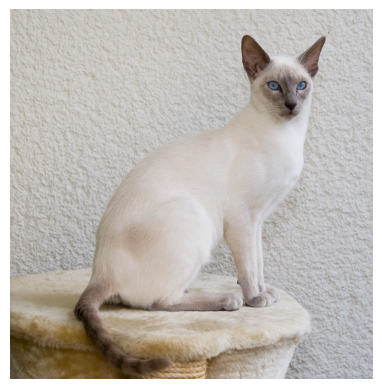

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step
Raw Prediction Value: 0.023554077371954918
Prediction: It's a CAT!


In [19]:
# ==========================================
# 7. INFERENCE (PREDICTING ON NEW IMAGES)
# ==========================================
# Replace path with your actual test image path (e.g., 'cat.jpg' or 'dog.jpg')
image_path = '/home/bhagat-singh/deep_learning/Siam_lilacpoint.jpg'
import cv2
if os.path.exists(image_path):
    test_img = cv2.imread(image_path)
    # Convert BGR (OpenCV default) to RGB for correct matplotlib plotting
    test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
    plt.imshow(test_img_rgb)
    plt.axis('off')
    plt.show()

    # Preprocess the image to fit model expectations
    test_img_resized = cv2.resize(test_img, (256, 256))
    test_input = test_img_resized.reshape((1, 256, 256, 3))

    # Scale image pixels if the training pipeline scales them
    test_input = test_input / 255.0

    # Prediction
    prediction = model.predict(test_input)
    print(f"Raw Prediction Value: {prediction[0][0]}")

    if prediction[0][0] < 0.5:
        print("Prediction: It's a CAT!")
    else:
        print("Prediction: It's a DOG!")
else:
    print(f"Image not found at {image_path}. Please check your path.")

In [17]:
model.evaluate(test_ds)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9222 - loss: 0.2708


[0.2708478271961212, 0.9222000241279602]

In [18]:
model.save('Cat_Vs_Dog.keras')

In [ ]:
model.predict()